# World at the final simulation step

Read `data/log_eden.tsv`, select every cell whose `death_date` equals the maximum recorded value, and plot its lattice position colored by `states`.

The log must include `position_x` and `position_y`. For new simulations, run `eden.ipynb` with the updated `sim.py`; restart its kernel first if the simulation module is already loaded.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Support running from either eden_sim/ or the project directory.
SIM_DIR = Path.cwd() / "eden_sim" if Path("eden_sim").is_dir() else Path.cwd()
log_file = SIM_DIR / "data" / "log_eden.tsv"

df = pd.read_csv(
    log_file,
    sep="\t",
    dtype={
        "id": "string", "generation": "int", "death_date": "int", "states": "string",
        "position_x": "int", "position_y": "int",
    },
)

In [2]:
final_death_date = df["death_date"].max()
final_cells = df.loc[df["death_date"].eq(final_death_date)].copy()

state_colors = {"edge": "#E69F00", "center": "#0072B2"}

print(f"Final death_date: {final_death_date}")
print(f"Cells selected: {len(final_cells)}")

Final death_date: 41
Cells selected: 1000


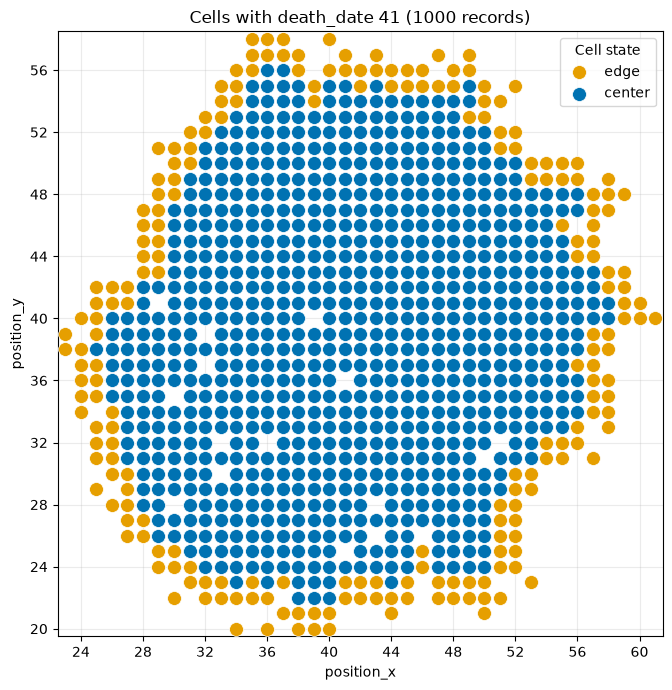

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))

for state, color in state_colors.items():
    cells = final_cells.loc[final_cells["states"].eq(state)]
    if cells.empty:
        continue
    ax.scatter(
        cells["position_x"], cells["position_y"],
        marker="o", s=100, color=color,
        edgecolors="white", linewidths=0.5,
        zorder=3, label=state,
    )

ax.set_title(f"Cells with death_date {final_death_date} ({len(final_cells)} records)")
ax.set_xlabel("position_x")
ax.set_ylabel("position_y")
ax.set_aspect("equal", adjustable="box")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(final_cells["position_x"].min() - 0.5, final_cells["position_x"].max() + 0.5)
ax.set_ylim(final_cells["position_y"].min() - 0.5, final_cells["position_y"].max() + 0.5)
ax.grid(True, alpha=0.25, zorder=0)
ax.legend(title="Cell state")
fig.tight_layout()
plt.show()

Cells removed by `end_sim()` have states calculated from the intact final world and are logged with `death_date = final simulation step + 1`. Ordinary deaths and divisions retain their actual simulation step, so `death_date == max(death_date)` selects the final survivors.

Calculate `birth_rate = generation / tick` for each final survivor. The actual simulation tick is `max(death_date) - 1`, because `end_sim()` records cleanup deaths one step later.

In [4]:
tick = int(final_death_date) - 1
if tick <= 0:
    raise ValueError("birth_rate = generation / tick requires at least one completed simulation tick.")

final_cells["birth_rate"] = final_cells["generation"] / tick

print(f"Simulation tick: {tick}")
print(f"Birth rate range: {final_cells['birth_rate'].min():.3f} to {final_cells['birth_rate'].max():.3f}")

Simulation tick: 40
Birth rate range: 0.200 to 0.850


In [7]:
from pathlib import Path

out_path = Path("data/birth_rates.tsv")
out_path.parent.mkdir(parents=True, exist_ok=True)
final_cells[["id", "birth_rate"]].to_csv(out_path, sep="\t", index=False)

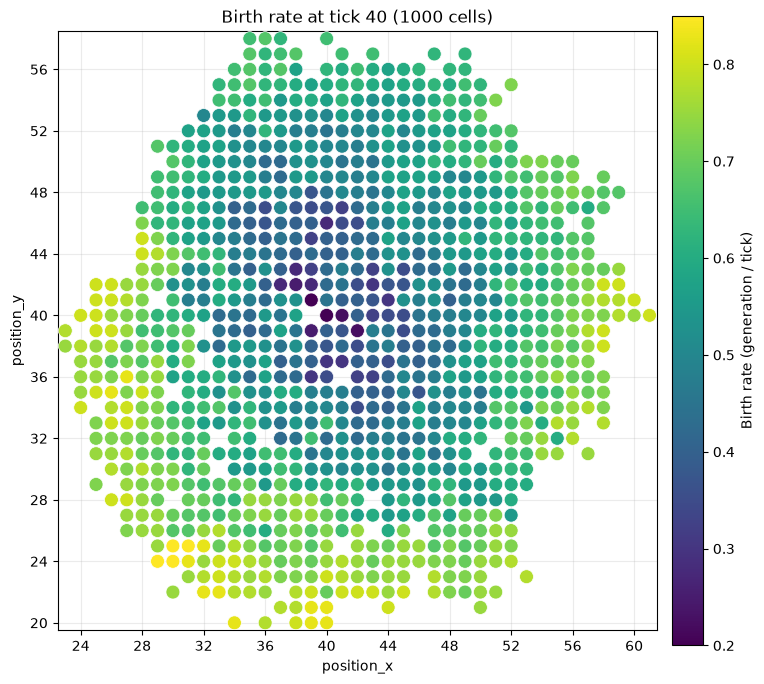

In [8]:
fig_birth_rate, ax_birth_rate = plt.subplots(figsize=(8, 7))

birth_rate_points = ax_birth_rate.scatter(
    final_cells["position_x"], final_cells["position_y"],
    c=final_cells["birth_rate"], cmap="viridis",
    marker="o", s=100, edgecolors="white", linewidths=0.5,
    zorder=3,
)
colorbar = fig_birth_rate.colorbar(birth_rate_points, ax=ax_birth_rate, pad=0.02)
colorbar.set_label("Birth rate (generation / tick)")

ax_birth_rate.set_title(f"Birth rate at tick {tick} ({len(final_cells)} cells)")
ax_birth_rate.set_xlabel("position_x")
ax_birth_rate.set_ylabel("position_y")
ax_birth_rate.set_aspect("equal", adjustable="box")
ax_birth_rate.xaxis.set_major_locator(MaxNLocator(integer=True))
ax_birth_rate.yaxis.set_major_locator(MaxNLocator(integer=True))
ax_birth_rate.set_xlim(final_cells["position_x"].min() - 0.5, final_cells["position_x"].max() + 0.5)
ax_birth_rate.set_ylim(final_cells["position_y"].min() - 0.5, final_cells["position_y"].max() + 0.5)
ax_birth_rate.grid(True, alpha=0.25, zorder=0)
fig_birth_rate.tight_layout()
plt.show()